# Diferença pareada de RMSE com IC 95% por bootstrap em blocos

O runner do pm25bench calcula um intervalo de confiança para cada modelo separadamente. Dois intervalos que se sobrepõem não dizem se um modelo é melhor que o outro: os erros dos dois modelos nos mesmos dias são correlacionados (os dias difíceis são difíceis para todos), e essa correlação some quando cada intervalo é calculado sozinho. A pergunta certa é sobre a **diferença** de métricas, calculada nas mesmas reamostras para os dois modelos.

Este notebook lê as previsões que o benchmark gravou e calcula, por lead, o IC 95% de RMSE(A) − RMSE(B), em todas as amostras de teste e só nos dias em que a observação passa do P90 do treino.

O experimento é a **calibração da previsão do CAMS**: os modelos usam só a previsão emitida às 00 UTC de *t*, as observações até *t*−1 e o calendário, sem reanálise (ela não existe na manhã de *t*).

Convenção de sinal: B é sempre o `gbm_previsao`. Uma diferença **positiva** quer dizer que o RMSE de A é maior, ou seja, que o `gbm_previsao` erra menos.

## 1. Previsões e configuração

`predictions.csv` tem uma linha por modelo, data de emissão e lead, com a observação (`obs`) e a previsão (`pred`) em µg/m³. Como o benchmark avalia todos os modelos nas mesmas amostras, cada par (`issue_date`, `lead`) aparece uma vez para cada modelo, e é isso que permite o pareamento.

A configuração é carregada do mesmo YAML usado na execução, para que os cortes de treino e validação sejam exatamente os do benchmark.

In [1]:
# Path: caminhos de arquivos independentes do sistema operacional
# os: troca do diretório de trabalho
import os
from pathlib import Path

# matplotlib: gráficos
import matplotlib.pyplot as plt

# numpy: vetores e sorteios
import numpy as np

# pandas: tabelas
import pandas as pd

# leitura da configuração e divisão temporal do benchmark
from pm25bench import load_config, split_by_time

# RMSE com a mesma implementação usada pelo runner
from pm25bench.metrics import rmse

# raiz do plugin: o notebook roda de dentro de notebooks/ ou da raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# os caminhos da config (sisam_dir, cetesb_dir...) são relativos à raiz do plugin
os.chdir(RAIZ)
# configuração usada na execução com dados reais
CONFIG = RAIZ / "configs" / "benchmark_calibracao_previsao.yaml"
# carrega e valida o YAML
cfg = load_config(CONFIG)
# pasta de resultados definida no YAML (relativa à raiz do plugin)
RESULTADOS = RAIZ / cfg.output_dir
# lê as previsões, convertendo as colunas de data
pred = pd.read_csv(RESULTADOS / "predictions.csv", parse_dates=["issue_date", "target_date"])
# modelos presentes no arquivo
print("modelos:", sorted(pred["model"].unique()))
# número de linhas por modelo (deve ser igual para todos: amostras × leads)
print(pred.groupby("model").size())

modelos: ['climatology', 'dom_previsao', 'forecast_raw', 'gbm_previsao', 'linear_previsao', 'persistence']
model
climatology        1812
dom_previsao       1812
forecast_raw       1812
gbm_previsao       1812
linear_previsao    1812
persistence        1812
dtype: int64


## 2. P90 da observação, calculado só no treino

O limiar que define "dia extremo" é o percentil 90 da observação diária **no período de treino**. Se ele fosse calculado no teste, a definição de extremo dependeria dos próprios dados avaliados, e essa informação do teste vazaria para a regra de avaliação. Com o P90 fixado no treino, a regra é a mesma que se conheceria antes de olhar o teste.

A tabela diária é recarregada com `cfg.data.load()` (os dados vêm do cache, conferidos por hash) e dividida com `split_by_time`, com os mesmos cortes do benchmark.

In [2]:
# tabela diária completa (obs + rea_*), igual à usada pelo runner
df = cfg.data.load()
# divisão em blocos de tempo com os cortes do YAML
treino, validacao, teste = split_by_time(
    df, cfg.data.train_end, cfg.data.val_end, cfg.data.gap_days
)
# percentil 90 das observações válidas do treino
P90 = float(treino["obs"].dropna().quantile(0.90))
# mostra o limiar e o período de onde ele saiu
print(f"P90 do treino ({treino.index.min().date()} a {treino.index.max().date()}): {P90:.1f} µg/m³")

P90 do treino (2010-01-01 a 2021-12-31): 30.9 µg/m³


## 3. Bootstrap pareado por blocos

**Bootstrap.** A distribuição de uma estatística (aqui, a diferença de RMSE) é aproximada reamostrando os dados com reposição muitas vezes e recalculando a estatística em cada reamostra. Os quantis de 2,5% e 97,5% dessas réplicas formam o intervalo de confiança de 95% (método percentil).

**Blocos.** O MP2,5 diário é autocorrelacionado: o erro de hoje se parece com o de ontem. Reamostrar dias isolados trataria dias vizinhos como independentes e produziria intervalos estreitos demais. Por isso os dias são agrupados em blocos de `block_days` dias consecutivos (o rótulo do bloco é `dias desde 1970 // block_days`, a mesma regra do runner), e são os blocos inteiros que entram ou saem de cada reamostra, preservando a dependência dentro de cada semana.

**Pareamento.** Em cada reamostra, os **mesmos blocos** são usados para calcular a métrica de A e a de B. A variância da diferença é `Var(A) + Var(B) − 2·Cov(A, B)`; como os dois modelos erram mais nos mesmos dias, a covariância é positiva e o intervalo da diferença fica mais estreito (e correto) do que o que se deduziria comparando os dois intervalos separados.

A diferença é significativa a 95% quando o intervalo não contém zero.

In [3]:
def bootstrap_diferenca_pareada(df_a, df_b, metrica, block_days=7, n_boot=1000, seed=42):
    """IC da diferença metrica(A) - metrica(B) por bootstrap pareado em blocos.

    Parameters
    ----------
    df_a, df_b : pandas.DataFrame
        Previsões de dois modelos (colunas issue_date, lead, obs, pred).
    metrica : callable
        Função metrica(obs, pred) -> float.
    block_days : int
        Tamanho dos blocos de dias consecutivos.
    n_boot : int
        Número de reamostras.
    seed : int
        Semente do gerador aleatório.

    Returns
    -------
    tuple of float
        (estimativa pontual, limite de 2,5%, limite de 97,5%).
    """
    # alinha os dois modelos pelas mesmas amostras (data de emissão e lead)
    par = df_a.merge(df_b, on=["issue_date", "lead"], suffixes=("_a", "_b"))
    # as duas tabelas precisam ter as mesmas amostras
    if len(par) != len(df_a) or len(par) != len(df_b):
        raise ValueError("os dois modelos não têm as mesmas amostras")
    # a observação é a mesma para os dois modelos (sanidade do pareamento)
    assert np.allclose(par["obs_a"], par["obs_b"])
    # observação comum
    o = par["obs_a"].to_numpy()
    # previsão de A
    fa = par["pred_a"].to_numpy()
    # previsão de B
    fb = par["pred_b"].to_numpy()
    # dias desde 1970 de cada data de emissão
    dias = (par["issue_date"] - pd.Timestamp("1970-01-01")).dt.days.to_numpy()
    # rótulo do bloco, igual ao do runner
    blocos = dias // block_days
    # rótulos distintos e, para cada amostra, o índice do seu bloco
    rotulos, inverso = np.unique(blocos, return_inverse=True)
    # lista com as posições das amostras de cada bloco
    grupos = [np.flatnonzero(inverso == i) for i in range(len(rotulos))]
    # estimativa pontual com todas as amostras
    pontual = metrica(o, fa) - metrica(o, fb)
    # gerador com semente fixa (reprodutível)
    rng = np.random.default_rng(seed)
    # réplicas da diferença
    reps = np.empty(n_boot)
    # cada iteração é uma reamostra
    for i in range(n_boot):
        # sorteia tantos blocos quantos existem, com reposição
        sorteio = rng.integers(0, len(grupos), len(grupos))
        # junta as amostras dos blocos sorteados
        idx = np.concatenate([grupos[j] for j in sorteio])
        # diferença calculada nas MESMAS amostras para os dois modelos
        reps[i] = metrica(o[idx], fa[idx]) - metrica(o[idx], fb[idx])
    # quantis de 2,5% e 97,5% (intervalo percentil de 95%)
    lo, hi = np.quantile(reps, [0.025, 0.975])
    # devolve estimativa e limites
    return float(pontual), float(lo), float(hi)

## 4. Tabela por lead

Para cada lead, quatro comparações contra o `gbm_previsao`: `linear_previsao` (mesmas entradas, sem não linearidade), `dom_previsao` (reta local na janela de 6 dias), `persistence` (o baseline mais difícil de vencer nos primeiros leads) e `forecast_raw` (a previsão do CAMS sem correção).

A segunda tabela repete as contas só nos dias em que a observação passa do P90 do treino. Esse subconjunto é escolhido pelo valor observado, então ele mede como cada modelo se sai nos extremos, e não serve sozinho para escolher um modelo: um modelo que sempre prevê alto iria bem nele. O número de amostras é informado porque, com poucos dias, o intervalo fica largo e a conclusão fraca.

In [4]:
# modelo de referência (B) em todas as comparações
REFERENCIA = "gbm_previsao"
# modelos comparados com a referência (A)
COMPARADOS = ["linear_previsao", "dom_previsao", "persistence", "forecast_raw"]


def tabela_diferencas(previsoes):
    """Diferença RMSE(A) - RMSE(referência) por lead, com IC 95% pareado."""
    # linhas da tabela final
    linhas = []
    # percorre os leads em ordem
    for lead in sorted(previsoes["lead"].unique()):
        # previsões deste lead
        sub = previsoes[previsoes["lead"] == lead]
        # previsões da referência neste lead
        ref = sub[sub["model"] == REFERENCIA]
        # percorre os modelos comparados
        for nome in COMPARADOS:
            # previsões do modelo A neste lead
            mod = sub[sub["model"] == nome]
            # estimativa e IC com os mesmos parâmetros de bootstrap do benchmark
            d, lo, hi = bootstrap_diferenca_pareada(
                mod, ref, rmse, cfg.block_days, cfg.n_boot, cfg.seed
            )
            # guarda a linha
            linhas.append(
                {
                    # identificação da comparação
                    "comparacao": f"{nome} − {REFERENCIA}",
                    # lead em dias
                    "lead": lead,
                    # número de amostras usadas
                    "n": len(ref),
                    # diferença pontual de RMSE (µg/m³)
                    "dif_rmse": d,
                    # limite inferior do IC 95%
                    "ic_lo": lo,
                    # limite superior do IC 95%
                    "ic_hi": hi,
                    # significativa se o intervalo não contém zero
                    "significativa": not (lo <= 0 <= hi),
                }
            )
    # devolve como DataFrame
    return pd.DataFrame(linhas)


# todas as amostras de teste
tab_todas = tabela_diferencas(pred)
# só os dias com observação acima do P90 do treino
pred_p90 = pred[pred["obs"] > P90]
# diferenças no subconjunto de extremos
tab_p90 = tabela_diferencas(pred_p90)
# quantas amostras de extremo há em cada lead
print(
    "amostras com obs > P90 por lead:",
    pred_p90[pred_p90["model"] == REFERENCIA].groupby("lead").size().to_dict(),
)
# mostra a tabela de todas as amostras, com 2 casas decimais
display(tab_todas.round(2))

amostras com obs > P90 por lead: {0: 47, 1: 47, 2: 49, 3: 48}


,comparacao,lead,n,dif_rmse,ic_lo,ic_hi,significativa
0,linear_previsao − gbm_previsao,0,453,-0.71,-1.20,-0.22,True
1,dom_previsao − gbm_previsao,0,453,0.58,-0.07,1.23,False
2,persistence − gbm_previsao,0,453,0.46,-0.27,1.11,False
3,forecast_raw − gbm_previsao,0,453,9.16,6.67,11.91,True
4,linear_previsao − gbm_previsao,1,453,-0.47,-0.89,-0.02,True
5,dom_previsao − gbm_previsao,1,453,0.83,-0.14,1.98,False
6,persistence − gbm_previsao,1,453,1.96,0.81,2.93,True
7,forecast_raw − gbm_previsao,1,453,8.80,6.10,11.76,True
8,linear_previsao − gbm_previsao,2,453,-0.33,-0.82,0.14,False
9,dom_previsao − gbm_previsao,2,453,0.99,-0.36,2.32,False


In [5]:
# tabela restrita aos extremos (obs > P90 do treino)
display(tab_p90.round(2))

,comparacao,lead,n,dif_rmse,ic_lo,ic_hi,significativa
0,linear_previsao − gbm_previsao,0,47,-2.70,-4.15,-0.95,True
1,dom_previsao − gbm_previsao,0,47,-2.18,-5.09,0.82,False
2,persistence − gbm_previsao,0,47,-3.10,-4.92,-1.30,True
3,forecast_raw − gbm_previsao,0,47,3.85,-1.29,10.17,False
4,linear_previsao − gbm_previsao,1,47,-2.65,-3.77,-1.29,True
5,dom_previsao − gbm_previsao,1,47,-4.03,-6.59,-0.93,True
6,persistence − gbm_previsao,1,47,-2.15,-5.09,0.60,False
7,forecast_raw − gbm_previsao,1,47,0.99,-6.47,9.94,False
8,linear_previsao − gbm_previsao,2,49,-1.89,-3.34,-0.77,True
9,dom_previsao − gbm_previsao,2,49,-3.16,-6.01,0.03,False


## 5. Gráficos

Um painel por comparação. Cada ponto é a diferença de RMSE em um lead, e a barra é o IC 95%. A linha em zero marca "sem diferença": barras inteiramente acima de zero indicam que o `gbm` erra menos, e inteiramente abaixo indicam que o outro modelo erra menos. Os pontos de todas as amostras e os do subconjunto P90 ficam lado a lado, levemente deslocados no eixo x para não se sobreporem.

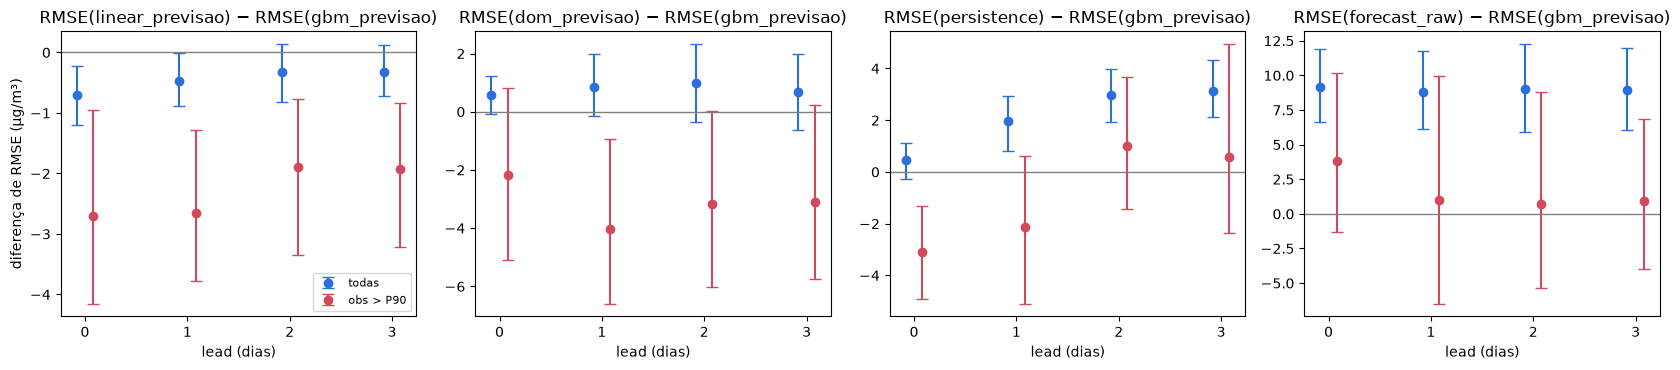

In [6]:
# uma coluna de painéis por comparação, eixo y independente
fig, eixos = plt.subplots(1, len(COMPARADOS), figsize=(4.2 * len(COMPARADOS), 3.8))
# percorre comparações e painéis juntos
for ax, nome in zip(eixos, COMPARADOS, strict=True):
    # duas séries: todas as amostras e só os extremos
    for tab, rotulo, desloc, cor in [
        (tab_todas, "todas", -0.08, "#2a6fdb"),
        (tab_p90, "obs > P90", 0.08, "#d1495b"),
    ]:
        # linhas desta comparação
        t = tab[tab["comparacao"] == f"{nome} − {REFERENCIA}"]
        # distância do ponto até cada limite, no formato que errorbar espera
        erro = [t["dif_rmse"] - t["ic_lo"], t["ic_hi"] - t["dif_rmse"]]
        # ponto com barra de erro, deslocado no eixo x
        ax.errorbar(
            t["lead"] + desloc,
            t["dif_rmse"],
            yerr=erro,
            fmt="o",
            capsize=4,
            color=cor,
            label=rotulo,
        )
    # linha de referência em zero
    ax.axhline(0, color="gray", lw=1)
    # título com a comparação
    ax.set_title(f"RMSE({nome}) − RMSE({REFERENCIA})")
    # leads inteiros no eixo x
    ax.set_xticks(sorted(pred["lead"].unique()))
    # rótulo do eixo x
    ax.set_xlabel("lead (dias)")
# rótulo do eixo y só no primeiro painel
eixos[0].set_ylabel("diferença de RMSE (µg/m³)")
# legenda no primeiro painel
eixos[0].legend(fontsize=8)
# ajusta espaçamentos
fig.tight_layout()
# mostra a figura
plt.show()